# Real-Data Evaluation — Bayyinah Burnout Model

The regression model was trained on a synthetic dataset. This notebook checks how it performs on real employees, using our own survey (52 respondents) as an external test set.

- **Features.** The model uses the 14 questions that the survey and the dataset share, plus `stress_score`. The survey has no direct stress question, so each respondent's `stress_score` is computed from their survey answers (section 4).
- **Label.** The survey measures burnout with the Burnout Assessment Tool (BAT-12, scored 1–5). It is normalized to 0–10, the scale of the synthetic `burnout_score`. The main metrics are **rank correlation** with BAT and **AUC** for detecting employees at risk.

The survey is used for testing only. Nothing in the model is fitted or tuned on it.

**Contents**
1. Survey data
2. BAT scores (normalized to 0–10)
3. Cleaning and mapping to model features
4. Stress score
5. Model (trained on synthetic data)
6. Evaluation on the survey
7. Which relationships hold in real data

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

from preprocessing import SEED, build_preprocessor, load_and_split

plt.rcParams["figure.dpi"] = 110

## 1. Survey data

In [2]:
survey = pd.read_csv("survey_responses.csv")
print(survey.shape)
survey.head()

(52, 28)


,timestamp,employment_status,gender,company_size,work_hours_per_week,meetings_per_day,deadline_pressure_score,sleep_hours_per_night,vacation_days_taken,social_support_score,...,bat_4,bat_5,bat_6,bat_7,bat_8,bat_9,bat_10,bat_11,bat_12,sees_therapist
0,20/11/2026 18:18:01,Full-time,Female,Startup (1-50),25.0,1.0,1,5.0,36,7,...,Sometimes,Rarely,Never,Rarely,Sometimes,Sometimes,Sometimes,Sometimes,Sometimes,No
1,20/11/2026 18:46:12,Full-time,Male,Large (1001-5000),48.0,1.0,6,9.0,30,10,...,Sometimes,Never,Never,Sometimes,Rarely,Rarely,Never,Never,Never,No
2,20/11/2026 19:03:20,Not employed,Female,Small (51-200),40.0,1.0,8,6.0,1,7,...,Often,Never,Often,Never,Rarely,Rarely,Rarely,Never,Often,No
3,20/11/2026 20:10:07,Full-time,Male,Large (1001-5000),45.0,1.0,1,6.0,0,10,...,Rarely,Rarely,Sometimes,Sometimes,Never,Never,Never,Rarely,Sometimes,No
4,20/11/2026 20:12:45,Part-time,Male,Startup (1-50),6.0,2.0,2,5.5,12,2,...,Sometimes,Sometimes,Rarely,Rarely,Often,Always,Never,Sometimes,Often,No


In [3]:
for c in ["employment_status", "gender", "company_size", "seniority_level", "uses_ai_tools", "sees_therapist"]:
    print(f"{c}: {survey[c].value_counts().to_dict()}")

employment_status: {'Full-time': 43, 'Part-time': 6, 'Not employed': 3}
gender: {'Male': 30, 'Female': 22}
company_size: {'Startup (1-50)': 15, 'Small (51-200)': 12, 'Large (1001-5000)': 10, 'Enterprise (5000+)': 9, 'Mid (201-1000)': 6}
seniority_level: {'Mid': 18, 'Senior': 13, 'Junior': 6, 'Manager': 6, 'Principal': 5, 'Lead': 4}
uses_ai_tools: {'Yes': 34, 'No': 18}
sees_therapist: {'No': 49, 'Yes': 2, 'Prefer not to say': 1}


## 2. BAT scores (normalized to 0–10)

Each BAT-12 item is scored 1 (Never) to 5 (Always). The total score is the mean of the 12 items, and each subscale is the mean of its 3 items (BAT manual v2.0). Risk zones use the manual's clinical cut-offs for the BAT-12 total score.

**Normalization.** The synthetic `burnout_score` runs from 0 to 10, so every BAT score (total and subscales) is mapped linearly from 1–5 to 0–10: `(BAT − 1) / 4 × 10`. 1 becomes 0, 3 becomes 5 and 5 becomes 10. A linear mapping keeps the order of respondents, so the risk zones are the same as before; only the cut-off values move (2.54 → 3.85 and 2.96 → 4.90).

In [4]:
scale = {"Never": 1, "Rarely": 2, "Sometimes": 3, "Often": 4, "Always": 5}
items = [f"bat_{i}" for i in range(1, 13)]
bat_items = survey[items].replace(scale).astype(int)

subscales = {"exhaustion": items[0:3], "mental_distance": items[3:6],
             "cognitive_impairment": items[6:9], "emotional_impairment": items[9:12]}
bat = pd.DataFrame({name: bat_items[cols].mean(axis=1) for name, cols in subscales.items()})
bat["bat_total"] = bat_items.mean(axis=1)


def normalize(score):
    # BAT 1-5 -> 0-10, the scale of the synthetic burnout_score
    return (score - 1) / 4 * 10


for col in list(subscales) + ["bat_total"]:
    bat[col] = normalize(bat[col])

# clinical cut-offs for the BAT-12 total score (BAT manual v2.0, Table 6), normalized to 0-10
AT_RISK, VERY_HIGH = normalize(2.54), normalize(2.96)
print(f"normalized cut-offs: at risk >= {AT_RISK:.2f}, very high risk >= {VERY_HIGH:.2f}")
bat["zone"] = pd.cut(bat["bat_total"], [-0.01, normalize(2.53), normalize(2.95), 10],
                     labels=["Green (no risk)", "Orange (at risk)", "Red (very high risk)"])
bat["at_risk"] = (bat["bat_total"] >= AT_RISK - 1e-9).astype(int)

print(bat["bat_total"].describe().round(2))
bat["zone"].value_counts().sort_index()

normalized cut-offs: at risk >= 3.85, very high risk >= 4.90
count    52.00
mean      3.75
std       1.50
min       0.21
25%       2.71
50%       3.75
75%       4.84
max       7.29
Name: bat_total, dtype: float64


zone
Green (no risk)         27
Orange (at risk)        12
Red (very high risk)    13
Name: count, dtype: int64

Cronbach's alpha: 0.828


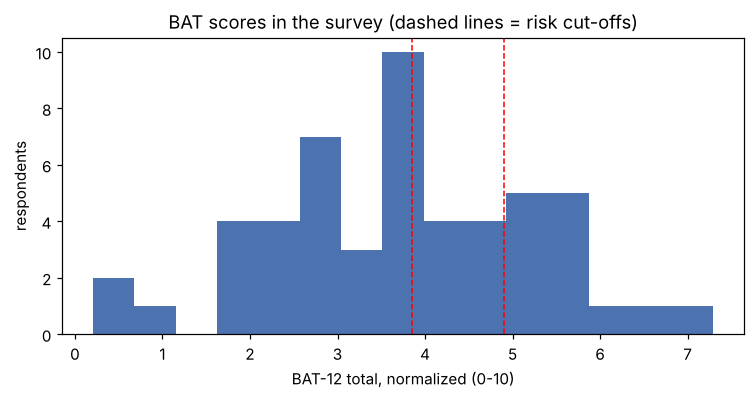

In [5]:
# internal consistency of the 12 items
k = len(items)
alpha = k / (k - 1) * (1 - bat_items.var(ddof=1).sum() / bat_items.sum(axis=1).var(ddof=1))
print(f"Cronbach's alpha: {alpha:.3f}")

plt.figure(figsize=(8, 3.5))
plt.hist(bat["bat_total"], bins=15, color="#4C72B0")
for x in [AT_RISK, VERY_HIGH]:
    plt.axvline(x, color="red", ls="--", lw=1)
plt.xlabel("BAT-12 total, normalized (0-10)")
plt.ylabel("respondents")
plt.title("BAT scores in the survey (dashed lines = risk cut-offs)")
plt.show()

## 3. Cleaning and mapping to model features

- **Work hours:** some full-time employees clearly answered with hours *per day* (e.g. 8). For respondents who are not part-time and reported fewer than 20 hours, the value is multiplied by 5. Part-time answers are kept as they are.
- **Vacation days:** capped at 30, the maximum in the training data.
- **AI tools / therapy:** Yes = 1, No = 0. "Prefer not to say" is left missing and filled by the pipeline's imputer.
- Gender, company size and seniority use the same categories as the training data.

In [6]:
s = survey.copy()

daily = (s["employment_status"] != "Part-time") & (s["work_hours_per_week"] < 20)
print("work hours multiplied by 5:", daily.sum())
s.loc[daily, "work_hours_per_week"] *= 5

print("vacation days capped at 30:", (s["vacation_days_taken"] > 30).sum())
s["vacation_days_taken"] = s["vacation_days_taken"].clip(upper=30)

s["ai_tools_daily"] = s["uses_ai_tools"].map({"Yes": 1, "No": 0})
s["uses_therapy"] = s["sees_therapist"].map({"Yes": 1, "No": 0})

work hours multiplied by 5: 12
vacation days capped at 30: 6


In [7]:
# the 14 questions both datasets share
FEATURES = [
    "work_hours_per_week", "meetings_per_day", "deadline_pressure_score", "sleep_hours_per_night",
    "vacation_days_taken", "social_support_score", "manager_support_score", "exercise_days_per_week",
    "autonomy_score", "ai_tools_daily", "uses_therapy", "seniority_level", "gender", "company_size",
]
X_survey = s[FEATURES]

X_train_all, X_test_all, y_train, y_test = load_and_split()
X_train, X_test = X_train_all[FEATURES], X_test_all[FEATURES]
stress_train, stress_test = X_train_all["stress_score"], X_test_all["stress_score"]

num = X_survey.select_dtypes("number").columns
pd.DataFrame({"synthetic min": X_train[num].min(), "synthetic max": X_train[num].max(),
              "synthetic mean": X_train[num].mean(), "survey min": X_survey[num].min(),
              "survey max": X_survey[num].max(), "survey mean": X_survey[num].mean()}).round(2)

,synthetic min,synthetic max,synthetic mean,survey min,survey max,survey mean
work_hours_per_week,35.0,72.0,47.10,5.0,88.0,39.24
meetings_per_day,0.0,12.0,4.16,0.0,3.5,1.12
deadline_pressure_score,1.0,10.0,6.38,1.0,10.0,5.98
sleep_hours_per_night,3.0,10.0,6.10,4.0,10.0,6.40
vacation_days_taken,0.0,30.0,12.06,0.0,30.0,13.60
social_support_score,1.0,10.0,5.38,1.0,10.0,6.48
manager_support_score,1.0,10.0,5.81,1.0,10.0,5.88
exercise_days_per_week,0.0,7.0,2.97,0.0,5.0,1.98
autonomy_score,1.0,10.0,5.84,1.0,10.0,6.29
ai_tools_daily,0.0,1.0,0.73,0.0,1.0,0.65


Most answers fall inside the training ranges. Part-time employees work fewer hours than anyone in the synthetic data (minimum 35), so the model has to extrapolate for them. Survey respondents also attend far fewer meetings (mean 1.1 per day vs 4.2), which matters for the stress score below.

## 4. Stress score

Each respondent's `stress_score` is computed from their answers to the 14 shared questions, using the relationship between these questions and `stress_score` in the synthetic training data.

### 4.1 Relationship of each question with stress in the synthetic data

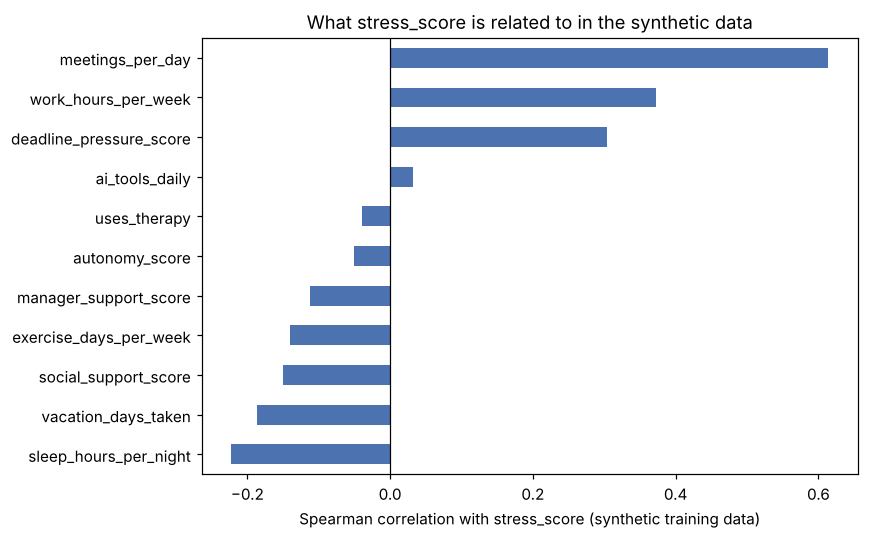

,Spearman rho with stress_score
sleep_hours_per_night,-0.222
vacation_days_taken,-0.187
social_support_score,-0.150
exercise_days_per_week,-0.141
manager_support_score,-0.113
autonomy_score,-0.050
uses_therapy,-0.039
ai_tools_daily,0.032
deadline_pressure_score,0.303
work_hours_per_week,0.373


In [8]:
num_feats = [f for f in FEATURES if f in X_train.select_dtypes("number").columns]
stress_corr = pd.DataFrame({
    "Spearman rho with stress_score": [spearmanr(X_train[f], stress_train)[0] for f in num_feats],
}, index=num_feats).sort_values("Spearman rho with stress_score")

ax = stress_corr.plot.barh(figsize=(8, 5), color="#4C72B0", legend=False)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Spearman correlation with stress_score (synthetic training data)")
ax.set_title("What stress_score is related to in the synthetic data")
plt.tight_layout()
plt.show()
stress_corr.round(3)

In [9]:
# categorical questions: mean stress per category
for c in ["seniority_level", "company_size", "gender"]:
    print(stress_train.groupby(X_train[c]).mean().round(2).sort_values().to_dict())

{'Junior': 6.52, 'Mid': 6.52, 'Senior': 6.52, 'Principal': 6.92, 'Lead': 8.85, 'Manager': 8.87}
{'Startup (1-50)': 7.03, 'Mid (201-1000)': 7.04, 'Enterprise (5000+)': 7.05, 'Large (1001-5000)': 7.07, 'Small (51-200)': 7.07}
{'Female': 7.04, 'Male': 7.06, 'Prefer not to say': 7.06}


In the synthetic data, stress is related mostly to **meetings per day** (ρ = 0.61), **work hours** (0.37) and **deadline pressure** (0.30), and is lower with more sleep, vacation and social support. Leads and managers have much higher stress (≈ 8.9) than other levels (6.5–6.9); company size and gender make almost no difference.

### 4.2 Computing the stress score

Ridge and HistGradientBoosting (same settings as the main model) are compared with a mean baseline using 5-fold cross-validation on the synthetic training set, using the same preprocessing as the burnout model. The one with the lowest CV MAE is used.

In [10]:
def make_model(estimator, X):
    return Pipeline([("prep", build_preprocessor(X)), ("model", estimator)])


def hgb():
    # same settings as the tuned main regression model
    return HistGradientBoostingRegressor(
        learning_rate=0.0715, max_iter=951, max_leaf_nodes=23, max_depth=3, min_samples_leaf=116,
        l2_regularization=1.631, max_features=0.817, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=30, random_state=SEED)


stress_bins = pd.qcut(stress_train, q=10, labels=False, duplicates="drop")
stress_cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, stress_bins))

stress_candidates = {"Dummy (mean)": DummyRegressor(), "Ridge": Ridge(alpha=1.0), "HistGradientBoosting": hgb()}
rows = []
for name, est in stress_candidates.items():
    scores = cross_validate(make_model(est, X_train), X_train, stress_train, cv=stress_cv,
                            scoring={"MAE": "neg_mean_absolute_error", "R2": "r2"})
    rows.append({"stress model": name, "CV MAE": -scores["test_MAE"].mean(), "CV R2": scores["test_R2"].mean()})
stress_cv_table = pd.DataFrame(rows).set_index("stress model")
stress_cv_table.round(4)

,CV MAE,CV R2
stress model,,
Dummy (mean),1.7794,-0.0000
Ridge,0.9425,0.6959
HistGradientBoosting,0.9038,0.7117


In [11]:
best_name = stress_cv_table.drop(index="Dummy (mean)")["CV MAE"].idxmin()
stress_model = make_model(stress_candidates[best_name], X_train).fit(X_train, stress_train)
S_MIN, S_MAX = stress_train.min(), stress_train.max()


def compute_stress(X):
    return np.clip(stress_model.predict(X), S_MIN, S_MAX)


stress_test_pred = compute_stress(X_test)
print("stress model:", best_name)
print("synthetic test MAE:", round(mean_absolute_error(stress_test, stress_test_pred), 3))
print("synthetic test R2: ", round(r2_score(stress_test, stress_test_pred), 3))

stress model: HistGradientBoosting
synthetic test MAE: 0.885
synthetic test R2:  0.715


Both models explain most of the stress score from the shared questions (CV R² ≈ 0.70), far better than the mean baseline. HistGradientBoosting is slightly better (CV MAE 0.90 vs 0.94) and is used to compute the stress score. On the held-out synthetic test set it explains 72% of the variance of `stress_score` (MAE 0.89).

### 4.3 Stress score for the survey respondents

In [12]:
s["stress_score"] = compute_stress(X_survey)

pd.DataFrame({"synthetic stress_score (real)": stress_train.describe(),
              "survey stress_score": s["stress_score"].describe()}).round(2)

,synthetic stress_score (real),survey stress_score
count,80000.00,52.00
mean,7.05,4.14
std,2.13,1.76
min,1.00,1.00
25%,5.50,3.23
50%,7.10,4.13
75%,8.80,5.05
max,10.00,8.48


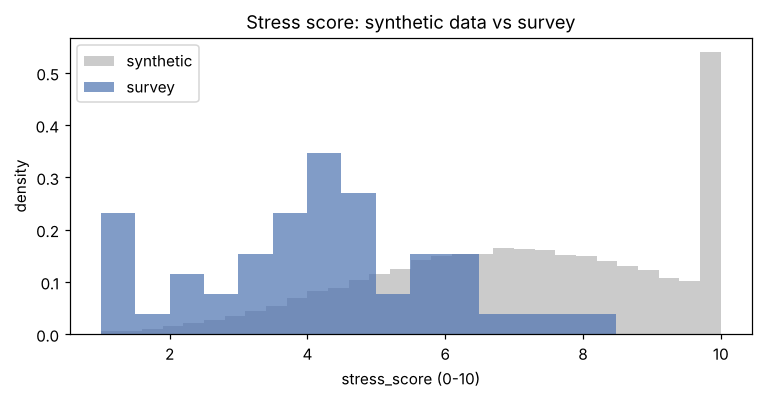

In [13]:
plt.figure(figsize=(8, 3.5))
plt.hist(stress_train, bins=30, density=True, alpha=0.5, color="#999999", label="synthetic")
plt.hist(s["stress_score"], bins=15, density=True, alpha=0.7, color="#4C72B0", label="survey")
plt.xlabel("stress_score (0-10)")
plt.ylabel("density")
plt.title("Stress score: synthetic data vs survey")
plt.legend()
plt.show()

Survey respondents have lower stress scores than the synthetic employees (mean 4.1 vs 7.1). The main reason is meetings, the strongest driver of stress in the synthetic data: survey respondents attend far fewer meetings (1.1 vs 4.2 per day).

## 5. Model

Same preprocessing as the main model, trained on the same synthetic training set, using the 14 shared questions plus `stress_score` (15 features). HistGradientBoosting uses the settings found when tuning the main regression model; Ridge is kept as a benchmark.

In [14]:
FEATURES_S = FEATURES + ["stress_score"]
X_train_s, X_test_s = X_train_all[FEATURES_S], X_test_all[FEATURES_S]
X_survey_s = s[FEATURES_S]

train_bins = pd.qcut(y_train, q=10, labels=False, duplicates="drop")
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train_s, train_bins))

models = {"Dummy (mean)": DummyRegressor(), "Ridge": Ridge(alpha=1.0), "HistGradientBoosting": hgb()}

rows = []
for name, est in models.items():
    scores = cross_validate(make_model(est, X_train_s), X_train_s, y_train, cv=cv,
                            scoring={"MAE": "neg_mean_absolute_error", "R2": "r2"})
    rows.append({"model": name, "CV MAE": -scores["test_MAE"].mean(), "CV R2": scores["test_R2"].mean()})
pd.DataFrame(rows).set_index("model").round(4)

,CV MAE,CV R2
model,,
Dummy (mean),2.2047,-0.0000
Ridge,0.8303,0.8488
HistGradientBoosting,0.8138,0.8530


In [15]:
fitted = {name: make_model(est, X_train_s).fit(X_train_s, y_train) for name, est in models.items()}
model = fitted["HistGradientBoosting"]

synthetic_pred = np.clip(model.predict(X_test_s), 0, 10)
print("synthetic test MAE:", round(mean_absolute_error(y_test, synthetic_pred), 3))
print("synthetic test R2: ", round(r2_score(y_test, synthetic_pred), 3))

synthetic test MAE: 0.8
synthetic test R2:  0.856


On the synthetic test set the model explains 86% of the variance of `burnout_score` (MAE 0.80). This is the model we test on real employees.

## 6. Evaluation on the survey

In [16]:
pred = np.clip(model.predict(X_survey_s), 0, 10)
ridge_pred = np.clip(fitted["Ridge"].predict(X_survey_s), 0, 10)
dummy_pred = np.full(len(s), y_train.mean())
y_bat = bat["bat_total"].values  # normalized to 0-10
rng = np.random.default_rng(SEED)


def bootstrap_ci(metric, *arrays, n=2000):
    vals = []
    for _ in range(n):
        idx = rng.integers(0, len(arrays[0]), len(arrays[0]))
        try:
            vals.append(metric(*[a[idx] for a in arrays]))
        except ValueError:
            continue
    return np.nanpercentile(vals, [2.5, 97.5])


results = []
for name, p in [("HistGradientBoosting", pred), ("Ridge", ridge_pred)]:
    rho, p_rho = spearmanr(p, y_bat)
    r, p_r = pearsonr(p, y_bat)
    auc = roc_auc_score(bat["at_risk"], p)
    rho_ci = bootstrap_ci(lambda a, b: spearmanr(a, b)[0], p, y_bat)
    auc_ci = bootstrap_ci(roc_auc_score, bat["at_risk"].values, p)
    results.append({"model": name,
                    "Spearman rho": rho, "rho 95% CI": f"[{rho_ci[0]:.2f}, {rho_ci[1]:.2f}]", "p (rho)": p_rho,
                    "Pearson r": r, "p (r)": p_r,
                    "AUC at-risk": auc, "AUC 95% CI": f"[{auc_ci[0]:.2f}, {auc_ci[1]:.2f}]"})
pd.DataFrame(results).set_index("model").round(3)

,Spearman rho,rho 95% CI,p (rho),Pearson r,p (r),AUC at-risk,AUC 95% CI
model,,,,,,,
HistGradientBoosting,0.427,"[0.15, 0.66]",0.002,0.465,0.001,0.670,"[0.51, 0.81]"
Ridge,0.443,"[0.16, 0.68]",0.001,0.485,0.000,0.674,"[0.51, 0.82]"


Baselines: a model with no information has a correlation of 0 and an AUC of 0.5.

The model's predictions are clearly related to real burnout: Spearman ρ = 0.43 (95% CI 0.15–0.66, p = 0.002), well above the no-information baseline of 0. It separates at-risk from not-at-risk employees better than chance (AUC = 0.67 vs 0.5), but the confidence interval is wide (0.51–0.81) because there are only 52 respondents. HistGradientBoosting and Ridge give similar results. These two metrics depend only on the order of respondents, so they are not affected by the normalization of BAT.

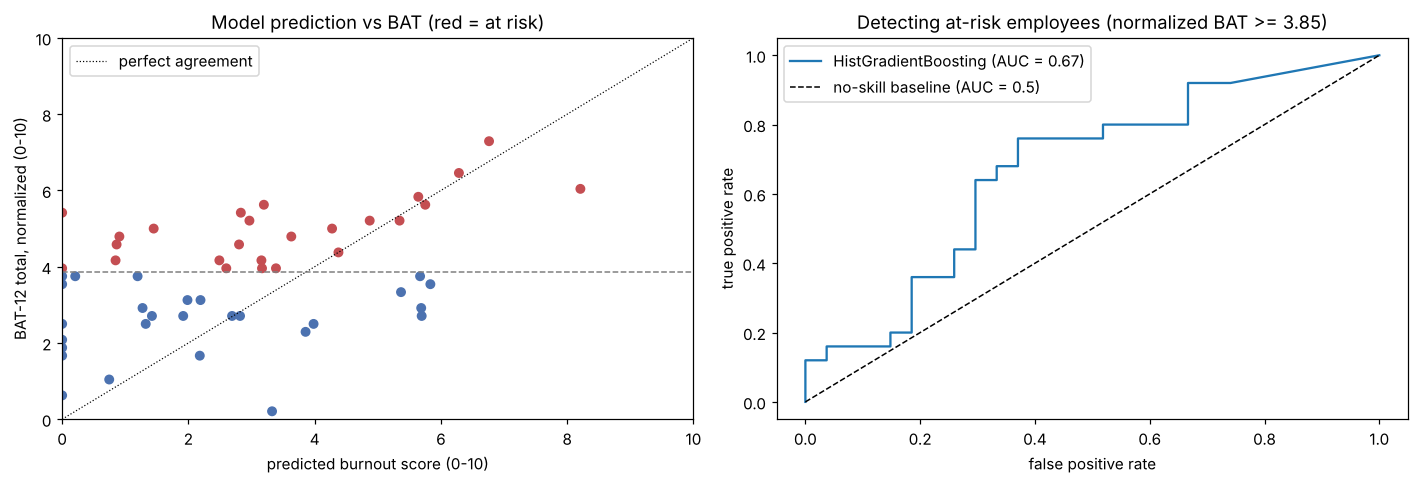

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colors = bat["at_risk"].map({0: "#4C72B0", 1: "#C44E52"})
axes[0].scatter(pred, y_bat, c=colors, s=30)
axes[0].plot([0, 10], [0, 10], color="black", lw=0.8, ls=":", label="perfect agreement")
axes[0].axhline(AT_RISK, color="grey", ls="--", lw=1)
axes[0].set(xlabel="predicted burnout score (0-10)", ylabel="BAT-12 total, normalized (0-10)",
            title="Model prediction vs BAT (red = at risk)", xlim=(0, 10), ylim=(0, 10))
axes[0].legend(loc="upper left")

fpr, tpr, _ = roc_curve(bat["at_risk"], pred)
axes[1].plot(fpr, tpr, label=f"HistGradientBoosting (AUC = {roc_auc_score(bat['at_risk'], pred):.2f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="no-skill baseline (AUC = 0.5)")
axes[1].set(xlabel="false positive rate", ylabel="true positive rate",
            title=f"Detecting at-risk employees (normalized BAT >= {AT_RISK:.2f})")
axes[1].legend()
plt.tight_layout()
plt.show()

Because the BAT score is now on the same 0–10 scale as the predictions, the absolute error can be reported directly. It is compared with a model that always predicts the training mean.

In [18]:
abs_rows = []
for name, p in [("HistGradientBoosting", pred), ("Ridge", ridge_pred), ("Dummy (mean)", dummy_pred)]:
    abs_rows.append({"model": name, "MAE vs normalized BAT": mean_absolute_error(y_bat, p),
                     "R2 vs normalized BAT": r2_score(y_bat, p), "mean prediction": p.mean()})
print("mean normalized BAT:", round(y_bat.mean(), 2))
pd.DataFrame(abs_rows).set_index("model").round(3)

mean normalized BAT: 3.75


,MAE vs normalized BAT,R2 vs normalized BAT,mean prediction
model,,,
HistGradientBoosting,1.770,-1.147,2.792
Ridge,1.990,-1.569,2.511
Dummy (mean),1.828,-1.234,5.402


On the common 0–10 scale, the model's MAE (1.77) is slightly better than always predicting the training mean (1.83), and both R² values are negative. The model ranks respondents reasonably well, but its predictions are lower on average than the normalized BAT scores (2.8 vs 3.75). The normalization puts both scores on the same range, but BAT and the synthetic `burnout_score` are different instruments, so their values are not directly comparable. Ranking (correlation) and at-risk detection (AUC) are therefore the main metrics.

In [19]:
pd.DataFrame({sub: spearmanr(pred, bat[sub])[0] for sub in list(subscales) + ["bat_total"]},
             index=["Spearman rho with prediction"]).T.round(3)

,Spearman rho with prediction
exhaustion,0.281
mental_distance,0.543
cognitive_impairment,0.213
emotional_impairment,0.068
bat_total,0.427


The model tracks mental distance and exhaustion best, and barely captures cognitive and emotional impairment. The synthetic data has no questions about these symptoms, so the model never learned them.

## 7. Which relationships hold in real data

For each numeric feature: its correlation with `burnout_score` in the synthetic training data, and with the BAT score in the survey. Same sign = the relationship the model learned also appears in real employees. For `stress_score`, the survey column uses the stress score from section 4.

In [20]:
num_feats_s = num_feats + ["stress_score"]
compare = pd.DataFrame({
    "synthetic (burnout_score)": [spearmanr(X_train_s[f], y_train)[0] for f in num_feats_s],
    "survey (BAT)": [spearmanr(X_survey_s[f], y_bat, nan_policy="omit")[0] for f in num_feats_s],
}, index=num_feats_s)
compare["same direction"] = np.sign(compare.iloc[:, 0]) == np.sign(compare.iloc[:, 1])
compare.round(3).sort_values("synthetic (burnout_score)")

,synthetic (burnout_score),survey (BAT),same direction
sleep_hours_per_night,-0.325,-0.205,True
vacation_days_taken,-0.270,-0.004,True
social_support_score,-0.211,-0.280,True
exercise_days_per_week,-0.204,-0.336,True
manager_support_score,-0.165,-0.459,True
autonomy_score,-0.083,-0.338,True
uses_therapy,-0.056,-0.117,True
ai_tools_daily,0.047,-0.003,False
deadline_pressure_score,0.138,0.270,True
meetings_per_day,0.441,-0.137,False


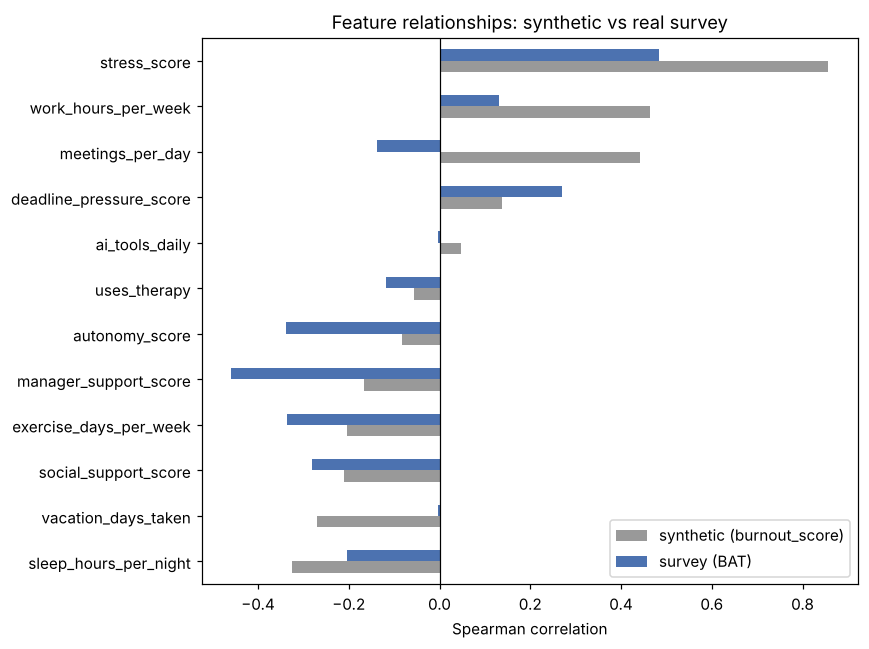

In [21]:
ax = compare.iloc[:, :2].sort_values("synthetic (burnout_score)").plot.barh(figsize=(8, 6), color=["#999999", "#4C72B0"])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Spearman correlation")
ax.set_title("Feature relationships: synthetic vs real survey")
plt.tight_layout()
plt.show()

10 of the 12 relationships keep the same direction in real data, so most of what the model learned carries over. `stress_score` is related to BAT in the expected direction (ρ = 0.48). The main difference is **meetings**: strongly linked to burnout in the synthetic data, but not in the survey. **Manager support** and **autonomy** matter more for real employees than the synthetic data suggests, while vacation days matter less.

## Summary

- On real employees, the model's predictions are moderately correlated with the BAT burnout score (ρ = 0.43) and detect at-risk employees better than chance (AUC = 0.67).
- Performance is lower than on synthetic data, which is expected: different respondents and a different burnout measure.
- Most feature relationships learned from the synthetic data also appear in the real data; meetings per day is the main exception.

**Limitations**
- Only 52 respondents, so all results have wide confidence intervals.
- BAT and the synthetic burnout score are different measures, so absolute errors cannot be compared directly, even after normalization.
- The BAT cut-offs come from Flemish employees; no cut-offs exist for Saudi employees yet.
- Some answers were corrected (work hours entered per day were multiplied by 5, vacation days capped at 30), and three respondents who are not currently employed answered about their last job.
- Respondents were not randomly sampled, so they may not represent all employees.